# FSPM2026 - Modeling Water Fluxes In The Soil-Plant System

### Coupling plant hydraulic architecture to a macroscopic soil grid
The following example simulates root water uptake by a growing root system from a drying soil. Temporal coupling as achieved  by solving each of the modules, plant and soil, sequentially, within each time step.  


No parameter file found. Continuing without parameter file.
Computed bounding box tree with 8499 nodes for 4250 grid entities in 0.000949106 seconds.
Computed bounding box tree with 8499 nodes for 4250 grid entities in 0.000941164 seconds.
Seed::initialize: RootSystem 
Organism::simulate: from 0 to 21 days
nodes moved 0
new nodes added 6274
segments added 6274
Number of segments 6275, including 6274 new 
PlantHydraulicModel.test():
6276 nodes:
Node 0 [ 0.1  0.  -3. ]
Node 1 [ 0.  0. -3.]
Node 2 [ 5.37687433e-03 -1.22059665e-03 -3.49996960e+00]
Node 3 [-5.70091119e-04 -9.35356738e-03 -3.99986808e+00]
Node 4 [-0.01307485  0.01946221 -4.3751959 ]
6275 segments:
Segment 0 [0 1] subType 0
Segment 1 [1 2] subType 1
Segment 2 [2 3] subType 1
Segment 3 [3 4] subType 1
Segment 4 [4 5] subType 2
Collar segment index 0
Collar segment [0 1]
0 segments with length < 1.e-5 cm
6 different root types from 0 to 5
ages from 0 to 21
segments 6275 6275

 -- Using the default temperature of 293.15 in the e

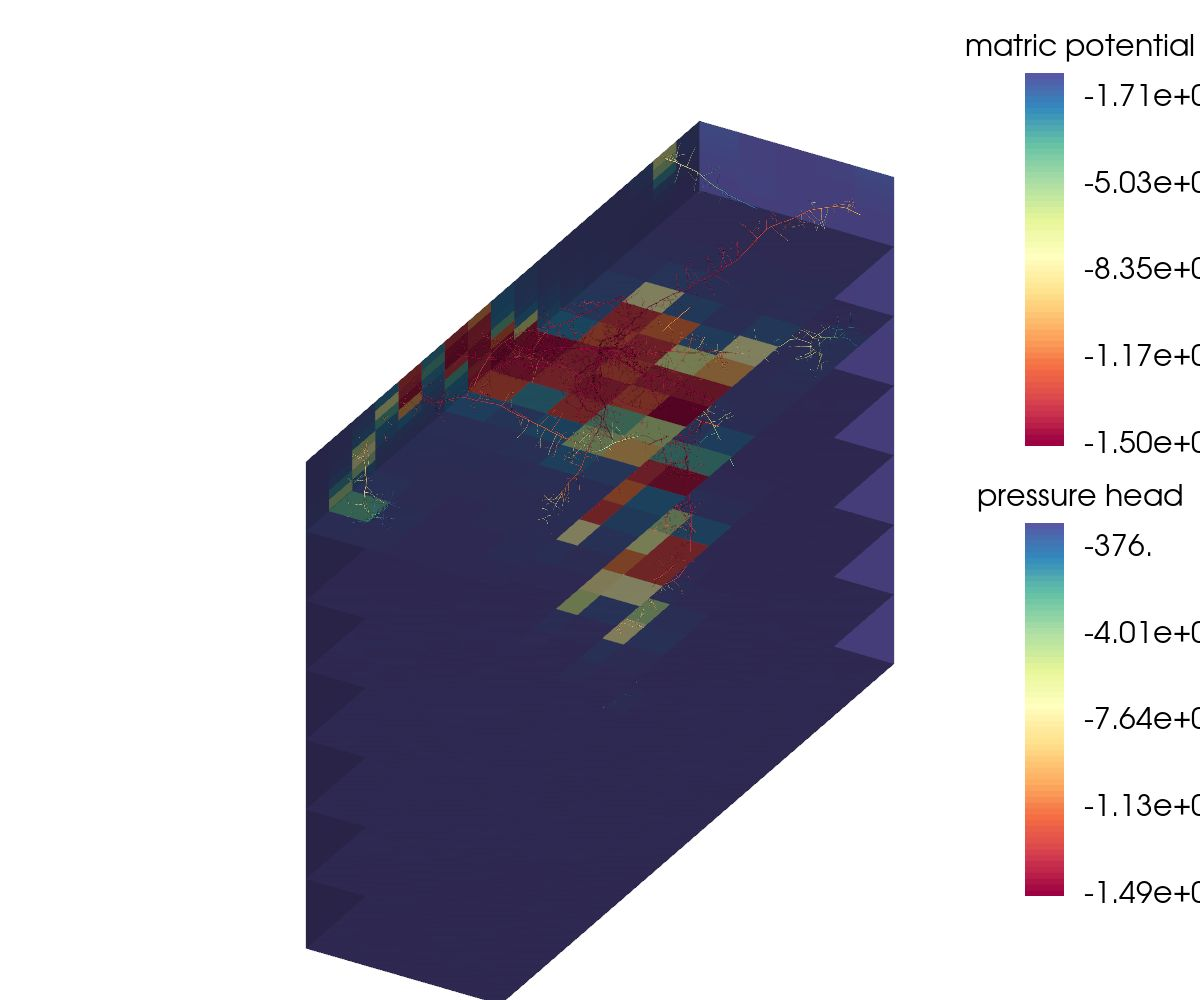

FileNotFoundError: [Errno 2] No such file or directory: 'results/Zeamays_synMRI_modified.npy'

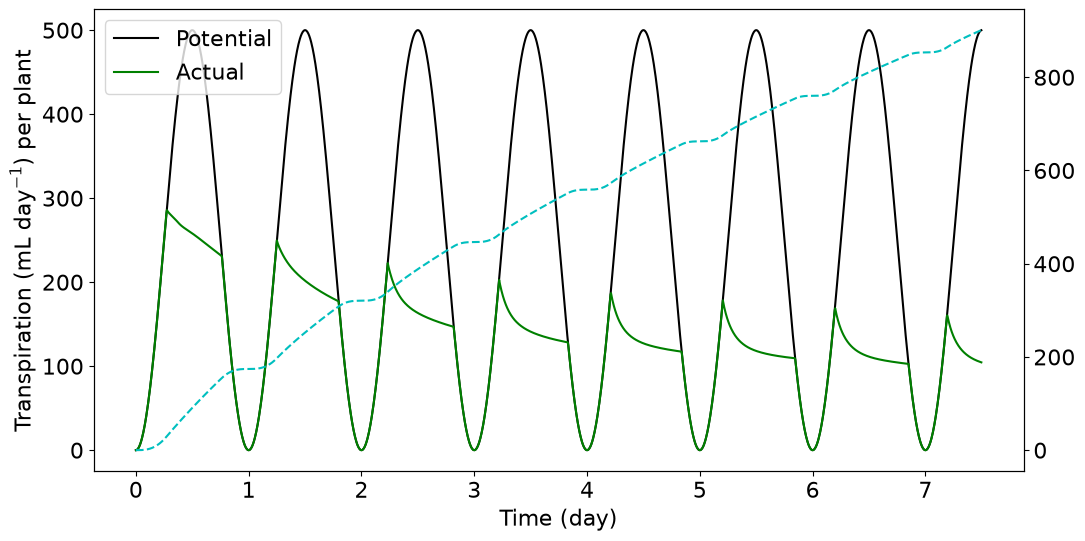

In [5]:
"""coupling with DuMux as solver for the soil part, dumux-rosi must be installed & compiled"""

import timeit

import matplotlib.pyplot as plt
import numpy as np

import plantbox as pb
import plantbox.visualisation.vtk_plot as vp
from plantbox.functional.PlantHydraulicModel import HydraulicModel_Doussan
from plantbox.functional.PlantHydraulicParameters import PlantHydraulicParameters
from plantbox.visualisation import figure_style
from rosi.richards import RichardsWrapper  # Python part
from rosi.rosi_richards import RichardsSP  # C++ part (Dumux binding)


def sinusoidal(t):
    """sinusoidal function (used for transpiration) (integral over one day is 1)"""
    return np.sin(2.0 * np.pi * np.array(t) - 0.5 * np.pi) + 1.0


# Parameters |\label{l72c:param}|
box_min = [-35.0, -10.0, -50.0]  # cm
box_max = [35.0, 10.0, 0.0]  # cm
cell_number = [17, 5, 50]  # ~4*4*1 cm3

path = pb.data_path() + "/structural/rootsystem/"
filename = "Zeamays_synMRI_modified"
t_pot = 250  # cm3 day-1 = mL day-1
wilting_point = -15000  # cm
plant_age = 21  # h_s_initial plant age (day)

loam = [0.078, 0.43, 0.036, 1.56, 24.96]  # hydrus loam
h_s_initial = -400  # cm

sim_time = 7.5  # days
dt = 360.0 / (24 * 3600)  # days |\label{l72c:param_end}|

# Initialize macroscopic soil model
s = RichardsWrapper(RichardsSP())  # |\label{l72c:soil}|
s.initialize()
s.createGrid(box_min, box_max, cell_number, periodic=True)  # cm
s.setHomogeneousIC(h_s_initial, True)  # cm total potential
s.setTopBC("noFlux")
s.setBotBC("noFlux")
s.setVGParameters([loam])
s.setParameter("Soil.SourceSlope", "100")  # |\label{l72c:regularisation}|
s.initializeProblem()
s.setCriticalPressure(wilting_point)  # |\label{l72c:soil_end}|

# Initialize xylem model
plant = pb.MappedPlant()  # |\label{l72c:soil_plant}|
plant.enableExtraNode()
plant.readParameters(path + filename + ".xml")
sdf = pb.SDF_PlantBox(np.inf, np.inf, box_max[2] - box_min[2])  # |\label{l72c:domain}|
plant.setGeometry(sdf)  # |\label{l72c:soil_plant_end}|

# Root hydraulic properties
params = PlantHydraulicParameters()  # |\label{l72c:hydraulic}|
params.read_parameters(pb.data_path() + "/functional/plant_hydraulics/couvreur2012")
# params.plot_conductivities(True) # |\label{l72c:plot_conductivities}|
hm = HydraulicModel_Doussan(plant, params)
hm.wilting_point = wilting_point  # |\label{l72c:hydraulic_end}|


# Coupling (map indices)
def picker(x, y, z):
    """soil grid cell index for position (x, y, z)"""
    return s.pick([x, y, z])  # |\label{l72c:coupling}|


plant.setSoilGrid(picker)
plant.initialize(True)
plant.simulate(plant_age, True)
hm.test()  # |\label{l72c:test}|

# Numerical solution
start_time = timeit.default_timer()
t = 0.0
sim_times_, t_act_ = [], []
n_steps = round(sim_time / dt)

for i in range(0, n_steps):  # |\label{l72c:loop}|
    plant.simulate(dt)  # |\label{l72c:plant}|
    h_s = s.getSolutionHead()  # |\label{l72c:h_s}|
    h_x = hm.solve(plant_age + t, -t_pot * sinusoidal(t), h_s, cells=True)  # |\label{l72c:h_x}|

    fluxes = hm.soil_fluxes(plant_age + t, h_x, h_s)  # |\label{l72c:soil_model}|
    s.setSource(fluxes)
    s.solve(dt)  # |\label{l72c:soil_model_end}|

    sim_times_.append(t)
    t_act_.append(float(hm.get_transpiration(plant_age + t, h_x, h_s, cells=True)))  # |\label{l72c:results}|

    n = round(float(i) / float(n_steps) * 100.0)  # |\label{l72c:progress}|
    print(
        f"[{'*' * n}{' ' * (100 - n)}], [{np.min(h_s):g}, {np.max(h_s):g}] cm soil [{np.min(h_x):g}, {np.max(h_x):g}] cm root at {s.simTime:g} days {h_x[0]:g}"
    )

    t += dt  # [day]

print("Coupled benchmark solved in ", timeit.default_timer() - start_time, " s")  # |\label{l72c:timing}|

# VTK visualisation |\label{l72c:plots}|
vp.plot_roots_and_soil(hm.ms.mappedSegments(), "matric potential", h_x, s, True, np.array(box_min), np.array(box_max), 
                       cell_number, interactiveImage = False)

# Transpiration over time
fig, ax1 = figure_style.subplots12(1, 1)
ax1.plot(sim_times_, t_pot * sinusoidal(sim_times_), "k")  # potential transpiration
ax1.plot(sim_times_, -np.array(t_act_), "g")  # actual transpiration
ax2 = ax1.twinx()
ax2.plot(sim_times_, np.cumsum(-np.array(t_act_) * dt), "c--")  # cumulative transpiratio
ax1.set_xlabel("Time (day)")
ax1.set_ylabel("Transpiration (mL day$^{-1}$) per plant")
ax1.legend(["Potential", "Actual", "Cumulative"], loc="upper left")
np.save("results/" + filename, np.vstack((sim_times_, -np.array(t_act_))))  # |\label{l72c:npsave}|
plt.show()
